<h2 style= "color: #60A5FA; text-align: left; font-weight: bold;">
Feed Recommendation Sysytem
</h2>

<h3 style= "color: #9CA3AF; text-align: left; font-weight: bold;">
1. Business Understanding
</h3>

An agricultural supply company wants to recommend similar feed types to farmers based on performance data

The objective is to use PCA and similarity metrics to suggest feeds that may produce results comparable to a feed the farmer already uses

The chicken weights dataset (`chickwts`) is used as a proxy for real feed performance data

**Success criteria:** the recommender should suggest feeds whose average chick weight is close to that of the feed the farmer currently uses

<h3 style= "color: #9CA3AF; text-align: left; font-weight: bold;">
2. Data Understanding
</h3>

In [1]:
# import required libs
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity, euclidean_distances

# load in the dataset
chick_df = pd.read_csv("chickwts.csv")

# display first few rows
chick_df.head()

,weight,feed
0,179,horsebean
1,160,horsebean
2,136,horsebean
3,227,horsebean
4,217,horsebean


The dataset comes from an experiment where newly hatched chicks were randomly given one of six feed supplements, and their weight was recorded after six weeks. Each row is one chick

| Column | Type | Meaning |
|---|---|---|
| `weight` | numeric (grams) | chick weight after six weeks. This is the performance measure |
| `feed` | categorical | the feed type the chick was given (the item we want to recommend) |

In [2]:
# check size, data types and missing values
print(chick_df.shape)
print(chick_df.dtypes)
print(chick_df.isna().sum())

(71, 2)
weight     int64
feed      object
dtype: object
weight    0
feed      0
dtype: int64


The dataset has 71 rows and 2 columns. `weight` is stored as a number and `feed` as text, which is what we expect. There are no missing values, so no cleaning is needed

In [3]:
# how many chicks per feed?
chick_df["feed"].value_counts()

feed
soybean      14
linseed      12
casein       12
sunflower    12
meatmeal     11
horsebean    10
Name: count, dtype: int64

There are 6 feeds with 10 to 14 chicks each (soybean has the most with 14, horsebean the fewest with 10). The groups are fairly balanced, but each one is small, so any statistic we calculate per feed will have some uncertainty

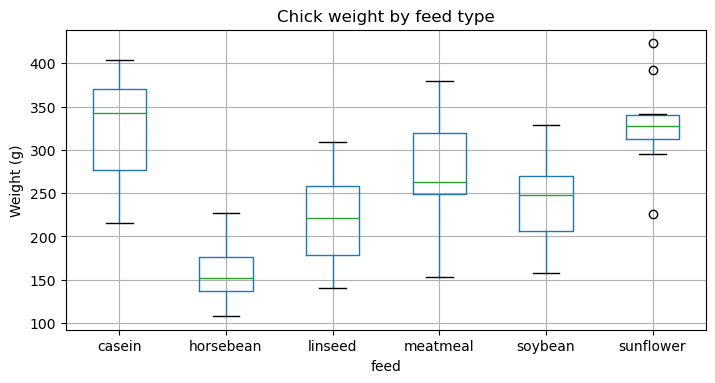

In [4]:
# compare chick weight across feeds
chick_df.boxplot(column="weight", by="feed", figsize=(8, 4))
plt.suptitle("")
plt.title("Chick weight by feed type")
plt.ylabel("Weight (g)")
plt.show()

**What the boxplot shows**

- **Horsebean** has the lowest weights (average about 160 g) and **linseed** is also low (about 219 g)
- **Soybean** (about 246 g) and **meatmeal** (about 277 g) sit in the middle
- **Casein** (about 324 g) and **sunflower** (about 329 g) give the heaviest chicks
- Weights across all chicks range from about 108 g to 423 g, so feed choice clearly affects results
- The boxes overlap between neighbouring feeds, so some feeds perform alike. This is exactly what a recommender can use

The feeds fall into three rough performance groups (low, medium, high). A good recommender should rediscover these groups, and we will use this as a check in the Evaluation phase

**Challenge:** there is only one numeric variable (`weight`), so there is little for PCA to work with directly. We solve this in Data Preparation by summarising each feed's weights into several statistics

In [ ]:
# Descriptive statistics of weight for each feed
chick_df.groupby("feed")["weight"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
feed,,,,,,,,
casein,12.0,323.6,64.4,216.0,277.2,342.0,370.8,404.0
horsebean,10.0,160.2,38.6,108.0,137.0,151.5,176.2,227.0
linseed,12.0,218.8,52.2,141.0,178.0,221.0,257.8,309.0
meatmeal,11.0,276.9,64.9,153.0,249.5,263.0,320.0,380.0
soybean,14.0,246.4,54.1,158.0,206.8,248.0,270.0,329.0
sunflower,12.0,328.9,48.8,226.0,312.8,328.0,340.2,423.0


The summary table gives the typical (mean) weight and the spread (std, min, max) for each feed. These are the same ideas we will use to build each feed's performance profile in the Data Preparation phase

<h3 style= "color: #9CA3AF; text-align: left; font-weight: bold;">
3.Data Preparation
</h3>

In [6]:
# build one performance profile per feed
profile = chick_df.groupby("feed")["weight"].agg(
    mean="mean",
    median="median",
    std="std",
    min="min",
    max="max",
    q25=lambda x: x.quantile(0.25),
    q75=lambda x: x.quantile(0.75),
).round(1)

profile

,mean,median,std,min,max,q25,q75
feed,,,,,,,
casein,323.6,342.0,64.4,216,404,277.2,370.8
horsebean,160.2,151.5,38.6,108,227,137.0,176.2
linseed,218.8,221.0,52.2,141,309,178.0,257.8
meatmeal,276.9,263.0,64.9,153,380,249.5,320.0
soybean,246.4,248.0,54.1,158,329,206.8,270.0
sunflower,328.9,328.0,48.8,226,423,312.8,340.2


**What the profile table shows**

Each row is now one feed, summarised by seven statistics of its chick weights:

| Feature | What it tells us |
|---|---|
| `mean`, `median` | typical weight. They are close for every feed, so there are no extreme outliers |
| `std` | consistency. Horsebean is the most consistent (38.6 g) and meatmeal the least (64.9 g) |
| `min`, `max` | worst and best case for the feed |
| `q25`, `q75` | the range where the middle 50% of chicks fall |

The feeds separate clearly by performance. Horsebean has the lowest mean (160.2 g), and sunflower (328.9 g) and casein (323.6 g) have the highest. Soybean (246.4 g) and meatmeal (276.9 g) sit in between

Most of these features rise and fall together, for example a feed with a high mean also has a high median and q75. This overlap is why PCA is useful in the next step, because it compresses these correlated features into a few components
PCA is driven by variance, so features are scaled to mean 0 and standard deviation 1 first

In [7]:
# scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(profile)

pd.DataFrame(X_scaled, index=profile.index, columns=profile.columns).round(2)

,mean,median,std,min,max,q25,q75
feed,,,,,,,
casein,1.09,1.29,1.16,1.18,0.89,0.84,1.28
horsebean,-1.68,-1.67,-1.68,-1.42,-1.79,-1.51,-1.77
linseed,-0.68,-0.59,-0.18,-0.63,-0.55,-0.82,-0.49
meatmeal,0.30,0.06,1.22,-0.34,0.52,0.38,0.48
soybean,-0.22,-0.17,0.03,-0.22,-0.25,-0.34,-0.30
sunflower,1.18,1.07,-0.55,1.42,1.17,1.44,0.80


<h3 style= "color: #9CA3AF; text-align: left; font-weight: bold;">
4.Modelling
</h3>

<h3 style= "color: #9CA3AF; text-align: left; font-weight: bold;">
4.1 PCA (dimensionality reduction)
</h3>

The profile features are highly correlated, so PCA compresses them into a few uncorrelated components. First check how much information each component keeps

Explained variance: [0.893 0.094 0.011 0.001 0.001 0.   ]
Cumulative: [0.893 0.987 0.999 0.999 1.    1.   ]


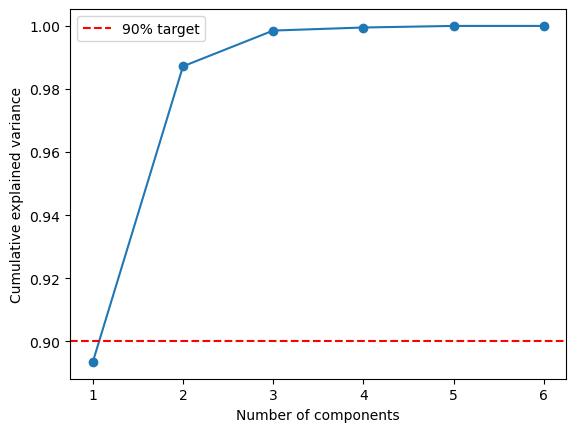

In [8]:
# fit PCA with all components to see explained variance
pca_full = PCA().fit(X_scaled)
explained = pca_full.explained_variance_ratio_

print("Explained variance:", explained.round(3))
print("Cumulative:", explained.cumsum().round(3))


plt.plot(range(1, len(explained) + 1), explained.cumsum(), marker="o")
plt.axhline(0.90, color="red", linestyle="--", label="90% target")
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.legend()
plt.show()

The first component alone keeps about 89% of the information in the profile table, and the first two together keep about 98.7%. The curve flattens after that, so the remaining components add almost nothing and mostly capture noise

The 7 profile features are highly correlated (a feed with a high mean also has a high median and q75), which is why they compress so well

In [9]:
# we keep the smallest number of components that explain at least 90% of the variance
n_components = int(np.argmax(explained.cumsum() >= 0.90) + 1)
print("Components kept:", n_components)

pca = PCA(n_components=n_components)
X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(X_pca, index=profile.index,
                      columns=[f"PC{i+1}" for i in range(n_components)])
pca_df.round(2)

Components kept: 2


,PC1,PC2
feed,,
casein,2.91,0.35
horsebean,-4.33,-0.53
linseed,-1.52,0.31
meatmeal,0.91,1.15
soybean,-0.57,0.18
sunflower,2.62,-1.45


We keep the smallest number of components that explain at least 90% of the variance. This gives 2 components, reducing 7 features to 2 while keeping almost all of the information

Each feed now has two coordinates (PC1 and PC2). Feeds with similar coordinates perform alike

In [10]:
# loadings show which original features drive each component
loadings = pd.DataFrame(pca.components_.T, index=profile.columns, columns=pca_df.columns)
loadings.round(2)

,PC1,PC2
mean,0.40,-0.09
median,0.40,-0.09
std,0.28,0.88
min,0.38,-0.38
max,0.40,-0.01
q25,0.39,-0.22
q75,0.40,0.15


Loadings show how much each original feature contributes to a component

- **PC1** has similar positive loadings (about 0.4) on mean, median, min, max, q25 and q75. A high PC1 means a feed gives heavier chicks overall, so PC1 is the **overall performance level** axis
- **PC2** is dominated by `std` (loading about 0.88). It captures **how consistent** a feed is, separating feeds with wide spread from feeds with steady results

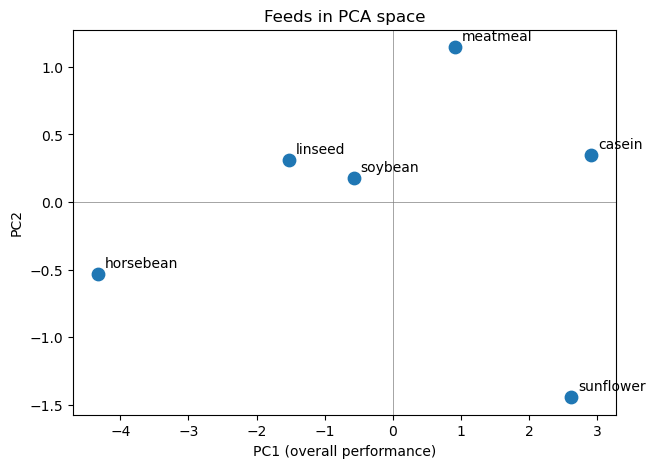

In [11]:
# plot the feeds in PCA space
plt.figure(figsize=(7, 5))
plt.scatter(pca_df["PC1"], pca_df["PC2"], s=80)
for feed, row in pca_df.iterrows():
    plt.annotate(feed, (row["PC1"], row["PC2"]), xytext=(5, 5), textcoords="offset points")
plt.xlabel("PC1 (overall performance)")
plt.ylabel("PC2")
plt.title("Feeds in PCA space")
plt.axhline(0, color="grey", lw=0.5)
plt.axvline(0, color="grey", lw=0.5)
plt.show()

The plot confirms the groups we saw in the boxplot

- **Horsebean** is far left (PC1 about -4.3), the lowest performer
- **Sunflower** and **casein** are far right (PC1 about 2.6 to 2.9), the highest performers
- **Linseed**, **soybean** and **meatmeal** fall in between
- Meatmeal has the highest PC2, reflecting its wide spread of weights, while sunflower has the lowest PC2 because its results are the most consistent among the heavier feeds

Feeds that sit close together in this plot are the ones the recommender will suggest as alternatives

<h3 style= "color: #9CA3AF; text-align: left; font-weight: bold;">
4.2 Similarity metrics
</h3>

Two metrics are compared on the PCA scores:

- **Cosine similarity** compares the *direction* of two feeds from the average feed
- **Euclidean distance** measures the straight-line distance, so it respects the size of the performance gap. It is converted to a similarity: `1 / (1 + distance)`

In [12]:
# cosine similarity
cos_df = pd.DataFrame(cosine_similarity(X_pca), index=profile.index, columns=profile.index).round(2)
cos_df

feed,casein,horsebean,linseed,meatmeal,soybean,sunflower
feed,,,,,,
casein,1.00,-1.00,-0.95,0.71,-0.91,0.81
horsebean,-1.00,1.00,0.95,-0.71,0.91,-0.81
linseed,-0.95,0.95,1.00,-0.45,1.00,-0.95
meatmeal,0.71,-0.71,-0.45,1.00,-0.36,0.16
soybean,-0.91,0.91,1.00,-0.36,1.00,-0.98
sunflower,0.81,-0.81,-0.95,0.16,-0.98,1.00


Cosine similarity ranges from -1 to 1 and compares the *direction* of two feeds from the average feed in PCA space

- Feeds on the same side of the average have positive scores, for example linseed and soybean (1.00), or casein and sunflower (0.81)
- Feeds on opposite sides have negative scores, for example casein and horsebean (-1.00)

**Problem:** cosine ignores how far apart two feeds are. Soybean sits very close to the average feed, so its direction is unstable. Cosine rates soybean as 0.91 similar to horsebean, even though their average weights differ by about 85 g (246.4 g vs 160.2 g). It also gives linseed and soybean a perfect 1.00 even though they are not identical feeds

In [13]:
# euclidean-based similarity
dist = euclidean_distances(X_pca)
sim_df = pd.DataFrame(1 / (1 + dist), index=profile.index, columns=profile.index).round(2)
sim_df

feed,casein,horsebean,linseed,meatmeal,soybean,sunflower
feed,,,,,,
casein,1.00,0.12,0.18,0.32,0.22,0.36
horsebean,0.12,1.00,0.25,0.15,0.21,0.12
linseed,0.18,0.25,1.00,0.28,0.51,0.18
meatmeal,0.32,0.15,0.28,1.00,0.36,0.24
soybean,0.22,0.21,0.51,0.36,1.00,0.22
sunflower,0.36,0.12,0.18,0.24,0.22,1.00


This metric turns the straight-line distance between two feeds in PCA space into a similarity score using `1 / (1 + distance)`. A score of 1 means identical, and scores fall towards 0 as feeds get further apart

Because it accounts for distance, it gives more sensible results

- Soybean's closest feed is **linseed** (0.51), followed by **meatmeal** (0.36), which are the feeds with the nearest average weights
- Horsebean is not similar to any feed (all scores 0.25 or less), which makes sense because it is the lowest performer by a wide margin
- Casein and sunflower, the two top performers, are each other's closest match (0.36)

We use this metric for the recommender

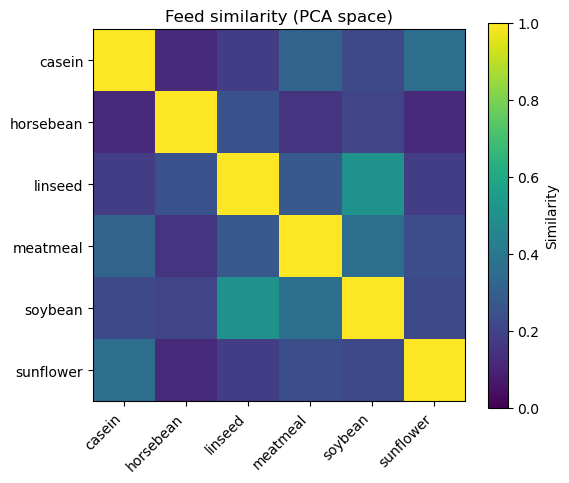

In [14]:
# heatmap of the chosen similarity matrix
plt.figure(figsize=(6, 5))
plt.imshow(sim_df, cmap="viridis", vmin=0, vmax=1)
plt.colorbar(label="Similarity")
plt.xticks(range(len(sim_df)), sim_df.columns, rotation=45, ha="right")
plt.yticks(range(len(sim_df)), sim_df.index)
plt.title("Feed similarity (PCA space)")
plt.show()

<h3 style= "color: #9CA3AF; text-align: left; font-weight: bold;">
4.2 Recommender Function
</h3>

Given a feed the farmer already uses, return the `n` most similar feeds (excluding itself) with their average chick weight

In [15]:
def recommend_feed(feed_name, n=2):
    # stop early if the feed is not in the data
    if feed_name not in sim_df.index:
        raise ValueError(f"Unknown feed '{feed_name}'. Choose from: {list(sim_df.index)}")

    # take the top n most similar feeds, excluding the feed itself
    scores = sim_df[feed_name].drop(feed_name).sort_values(ascending=False).head(n)

    return pd.DataFrame({
        "similarity": scores,
        "avg_weight_g": profile.loc[scores.index, "mean"],
    })

# example: farmer currently uses soybean
print("Current feed: soybean (avg", profile.loc["soybean", "mean"], "g)")
recommend_feed("soybean", n=2)

Current feed: soybean (avg 246.4 g)


,similarity,avg_weight_g
feed,,
linseed,0.51,218.8
meatmeal,0.36,276.9


<h3 style= "color: #9CA3AF; text-align: left; font-weight: bold;">
5. Evaluation
</h3>

There are no ground-truth labels for "similar feed", so we check the recommender against the business success criteria: does the top recommendation match the feed with the closest average weight?

In [16]:
# compare top recommendation with the closest feed by average weight
check = []
for feed in profile.index:
    top1 = recommend_feed(feed, n=1).index[0]
    gap = (profile["mean"] - profile.loc[feed, "mean"]).abs().drop(feed)
    closest_by_mean = gap.idxmin()
    check.append((feed, top1, closest_by_mean, top1 == closest_by_mean))

check_df = pd.DataFrame(check, columns=["feed", "top_recommendation", "closest_by_mean_weight", "agree"])
print("Agreement:", check_df["agree"].mean())
check_df

Agreement: 1.0


,feed,top_recommendation,closest_by_mean_weight,agree
0,casein,sunflower,sunflower,True
1,horsebean,linseed,linseed,True
2,linseed,soybean,soybean,True
3,meatmeal,soybean,soybean,True
4,soybean,linseed,linseed,True
5,sunflower,casein,casein,True


In [17]:
# recommendations for every feed
for feed in profile.index:
    top = recommend_feed(feed, n=2)
    print(f"{feed:10s} (avg {profile.loc[feed, 'mean']:.0f} g)  ->  ",
          ", ".join(f"{f} ({s:.2f})" for f, s in top["similarity"].items()))

casein     (avg 324 g)  ->   sunflower (0.36), meatmeal (0.32)
horsebean  (avg 160 g)  ->   linseed (0.25), soybean (0.21)
linseed    (avg 219 g)  ->   soybean (0.51), meatmeal (0.28)
meatmeal   (avg 277 g)  ->   soybean (0.36), casein (0.32)
soybean    (avg 246 g)  ->   linseed (0.51), meatmeal (0.36)
sunflower  (avg 329 g)  ->   casein (0.36), meatmeal (0.24)


**Results**

For each of the 6 feeds, we compared the recommender's top suggestion with the feed whose average chick weight is closest. They matched for all 6 feeds (agreement = 100%), so the recommender meets the success criteria from the Business Understanding phase

For example, a farmer using soybean (246.4 g average) is recommended linseed (218.8 g) first, then meatmeal (276.9 g). These are the two feeds with the nearest average weights, so the farmer can expect similar results

Choosing Euclidean-based similarity also paid off. With cosine similarity, meatmeal's top match was casein instead of soybean, so it matched the closest feed for only 5 of the 6 feeds

**How far to trust this**

This check is a sanity check, not a full validation. The recommender is built from weight statistics and is checked against average weight, so it is not an independent test. We also have no real farmer outcomes to compare against

**Limitations**

- **Small sample:** there are only 6 feeds and 10-14 chicks per feed, so statistics such as min and max can change a lot if a few chicks are different
- **Single performance measure:** weight is the only thing we measure. A real system should also consider cost, nutrition content and availability, since a similar feed is only useful if the farmer can get it at a fair price
- **No unseen feeds:** the recommender can only suggest feeds that are in the dataset

**Conclusion:** the recommender gives sensible, explainable suggestions on this data. It is a good prototype, and it can be improved by adding more feeds, more chicks and more features